# Laboratorio 7 — Task 3 (Entrega Final)
Grupo 3: $q=0.30$, $D=5$ días.

Este cuaderno reutiliza **sin cambios** las funciones verificadas en el Task 2 (`Task2.ipynb`): DES M/M/$c$/$K$, teoría M/M/$c$ y M/M/$c$/$K$, RK4 con $h=0.05$ y el híbrido con evento de estado localizado por bisección (`hibrido_eventos`).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import solve_ivp
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

def ic95(x):
    x = np.asarray(x, float); n = len(x)
    h = stats.t.ppf(.975, n-1)*x.std(ddof=1)/np.sqrt(n)
    return x.mean(), h
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda it, *a, **kw: it


In [2]:
import numpy as np, heapq
from collections import deque
from math import factorial

MU = 2.0

def simular_des(lam, c, K=60, T=720.0, warm=120.0, mu=MU, rng=None, vaciar=True, traza=False):
    """M/M/c/K FIFO. Mide sobre [warm, T].
    - W, Wq: de las solicitudes ACEPTADAS que llegan en [warm, T]; si vaciar=True se siguen
      hasta su salida (sin nuevas llegadas tras T) para no truncar sus tiempos.
    - L, Lq, ocupados: promedios temporales en [warm, T].
    - r: rechazadas / llegadas en [warm, T].
    Devuelve dict con métricas y contadores para balance de entidades."""
    rng = rng or np.random.default_rng()
    t = 0.0
    ev = []
    heapq.heappush(ev, (rng.exponential(1/lam), 0, -1))   # (t, tipo 0=llegada 1=salida, id)
    n = 0; ocup = 0; cola = deque()
    t_lleg = {}; t_ini = {}
    sig = 0
    # acumuladores temporales en [warm, T]
    aL = aLq = aB = 0.0; t_prev = 0.0
    W_list = []; Wq_list = []
    cnt = dict(lleg_tot=0, lleg_med=0, rech_tot=0, rech_med=0, atend_tot=0, atend_med=0,
               N_warm=None, N_T=None)
    medir = set()
    tr_t, tr_n = [0.0], [0]
    while ev:
        tn, tipo, cid = heapq.heappop(ev)
        if tipo == 0 and tn > T:          # no más llegadas tras T
            continue
        # integrar áreas entre t_prev y min(tn, T) dentro de [warm, T]
        a0, a1 = max(t_prev, warm), min(tn, T)
        if a1 > a0:
            aL += n*(a1-a0); aLq += (n-ocup)*(a1-a0); aB += ocup*(a1-a0)
        if cnt['N_warm'] is None and tn >= warm:
            cnt['N_warm'] = n
        if cnt['N_T'] is None and tn >= T:
            cnt['N_T'] = n
            if not vaciar:
                break
        t_prev = tn; t = tn
        if traza and tn <= T: tr_t.append(tn)
        if tipo == 0:
            heapq.heappush(ev, (t + rng.exponential(1/lam), 0, -1))
            cnt['lleg_tot'] += 1
            en_med = t >= warm
            cnt['lleg_med'] += en_med
            if n >= K:
                cnt['rech_tot'] += 1; cnt['rech_med'] += en_med
                if traza and len(tr_n) < len(tr_t): tr_n.append(n)
                continue
            cid = sig; sig += 1
            n += 1; t_lleg[cid] = t
            if en_med: medir.add(cid)
            if ocup < c:
                ocup += 1; t_ini[cid] = t
                heapq.heappush(ev, (t + rng.exponential(1/mu), 1, cid))
            else:
                cola.append(cid)
        else:
            n -= 1
            if t <= T:
                cnt['atend_tot'] += 1; cnt['atend_med'] += (t >= warm)
            if cid in medir:
                W_list.append(t - t_lleg[cid]); Wq_list.append(t_ini[cid] - t_lleg[cid])
            del t_lleg[cid]; t_ini.pop(cid, None)
            if cola:
                nid = cola.popleft(); t_ini[nid] = t
                heapq.heappush(ev, (t + rng.exponential(1/mu), 1, nid))
            else:
                ocup -= 1
        if traza and t <= T and len(tr_n) < len(tr_t): tr_n.append(n)
    if cnt['N_T'] is None: cnt['N_T'] = n
    if cnt['N_warm'] is None: cnt['N_warm'] = n
    Tm = T - warm
    acept_med = cnt['lleg_med'] - cnt['rech_med']
    return dict(W=np.mean(W_list) if W_list else 1/mu,
                Wq=np.mean(Wq_list) if Wq_list else 0.0,
                L=aL/Tm, Lq=aLq/Tm, B=aB/Tm, util=aB/Tm/c,
                lam_eff=acept_med/Tm,
                r=cnt['rech_med']/cnt['lleg_med'] if cnt['lleg_med'] else 0.0,
                traza=(np.array(tr_t), np.array(tr_n)) if traza else None, **cnt)

# ---------------- teoría ----------------
def erlang_c(c, A):
    s = sum(A**k/factorial(k) for k in range(c))
    tc = A**c/factorial(c)*c/(c-A)
    return tc/(s+tc)

def mmc(lam, c, mu=MU):
    A = lam/mu; C = erlang_c(c, A)
    Wq = C/(c*mu-lam)
    return dict(W=Wq+1/mu, Wq=Wq, util=A/c, Lq=lam*Wq, L=lam*(Wq+1/mu), C=C)

def mmck(lam, c, K, mu=MU):
    A = lam/mu
    p = np.array([A**n/factorial(n) if n <= c else A**c/factorial(c)*(A/c)**(n-c)
                  for n in range(K+1)], float)
    p /= p.sum()
    n = np.arange(K+1)
    L = (n*p).sum(); Lq = (np.maximum(n-c, 0)*p).sum()
    lam_eff = lam*(1-p[K])
    return dict(PK=p[K], L=L, Lq=Lq, W=L/lam_eff, Wq=Lq/lam_eff,
                util=lam_eff/(c*mu), lam_eff=lam_eff, p=p)


In [3]:
import numpy as np
from scipy.integrate import solve_ivp

# ---------------- parámetros (grupo 3) ----------------
P = dict(p=0.002, q=0.30, M=20000.0, U0=100.0, d0=0.003, kW=1.0, kR=0.5, Wok=0.75,
         a=0.0005, mu=MU, K=60, theta=0.7, lote=2, D=5.0, c0=4, T=100.0, H=1.0,
         h=0.05, modo='des')
# h = paso RK4 escogido en el Task 2.2; modo='des' (simulación) o 'teoria' (M/M/c/K exacta, sin ruido)

def f_U(U, P, W, r):
    delta = P['d0'] + P['kW']*max(0.0, W - P['Wok']) + P['kR']*r
    return (P['p'] + P['q']*U/P['M'])*(P['M'] - U) - delta*U

def rho_pred(U, c, P):
    return P['a']*U/(c*P['mu'])

def paso_rk4(U, h, P, W, r):
    k1 = f_U(U, P, W, r); k2 = f_U(U + h/2*k1, P, W, r)
    k3 = f_U(U + h/2*k2, P, W, r); k4 = f_U(U + h*k3, P, W, r)
    return U + h/6*(k1 + 2*k2 + 2*k3 + k4)

def intercambio(P, U, c, k, seed):
    """Ventana DES del intercambio k. Semilla (seed, k): números aleatorios comunes entre versiones."""
    lam = P['a']*U
    if P['modo'] == 'teoria':
        m = mmck(lam, c, P['K'], P['mu']); return m['W'], m['PK']
    out = simular_des(lam, c, K=P['K'], mu=P['mu'], rng=np.random.default_rng([seed, k]))
    return out['W'], out['r']

def _prep(P, feedback, kw):
    P = dict(P, **kw)
    if not feedback: P['kW'] = P['kR'] = 0.0
    return P

def _salida(ts, Us, U, c, pedidos, llegadas, log, P):
    log = np.array(log)
    return dict(t=np.array(ts), U=np.array(Us), U100=U, c=c, pedidos=pedidos,
                llegadas=llegadas, Wmax=log[:, 3].max(), rmax=log[:, 4].max(), log=log, P=P)

# ------------- (1) evento de estado con RK4 propio + bisección -------------
def hibrido_eventos(P=P, seed=0, feedback=True, tol=1e-10, **kw):
    P = _prep(P, feedback, kw)
    h, T, H = P['h'], P['T'], P['H']
    U_cr = lambda c: P['theta']*c*P['mu']/P['a']           # U donde rho_pred = theta
    U, c, t = P['U0'], P['c0'], 0.0
    t_arr = None; pedidos, llegadas = [], []
    k = 0; W, r = intercambio(P, U, c, k, seed)
    log = [(0.0, U, c, W, r)]; t_sig_H = H
    ts, Us = [0.0], [U]
    while t < T - 1e-12:
        # el paso nunca salta un evento de tiempo (intercambio o llegada)
        t_obj = min(t + h, t_sig_H, T, t_arr if t_arr is not None else np.inf)
        hh = t_obj - t
        U_new = paso_rk4(U, hh, P, W, r)
        g0, g1 = U - U_cr(c), U_new - U_cr(c)
        if t_arr is None and g0 < 0 <= g1:                  # cruce hacia arriba dentro del paso
            lo, hi = 0.0, hh                                # bisección sobre el sub-paso RK4
            while hi - lo > tol:
                mid = (lo + hi)/2
                if paso_rk4(U, mid, P, W, r) - U_cr(c) >= 0: hi = mid
                else: lo = mid
            t, U = t + hi, paso_rk4(U, hi, P, W, r)
            ts.append(t); Us.append(U)
            pedidos.append(t); t_arr = t + P['D']
            continue
        t, U = t_obj, U_new
        ts.append(t); Us.append(U)
        if t_arr is not None and abs(t - t_arr) < 1e-9:   # evento de tiempo: llegan servidores
            c += P['lote']; llegadas.append(t); t_arr = None
            if rho_pred(U, c, P) > P['theta']:              # reorden inmediato
                pedidos.append(t); t_arr = t + P['D']
        if abs(t - t_sig_H) < 1e-9 and t < T - 1e-12:      # intercambio SD -> DES -> SD
            k += 1; W, r = intercambio(P, U, c, k, seed); t_sig_H += H
            log.append((t, U, c, W, r))
    return _salida(ts, Us, U, c, pedidos, llegadas, log, P)

# ------------- (1b) la misma lógica con solve_ivp(events=...) para contraste -------------
def hibrido_eventos_ivp(P=P, seed=0, feedback=True, **kw):
    P = _prep(P, feedback, kw)
    T, H = P['T'], P['H']
    U, c, t = P['U0'], P['c0'], 0.0
    t_arr = None; pedidos, llegadas = [], []
    k = 0; W, r = intercambio(P, U, c, k, seed)
    log = [(0.0, U, c, W, r)]; t_sig_H = H
    ts, Us = [0.0], [U]
    while t < T - 1e-12:
        t_fin = min(t_sig_H, T, t_arr if t_arr is not None else np.inf)
        cc = c
        ev = lambda tt, y: rho_pred(y[0], cc, P) - P['theta']
        ev.terminal, ev.direction = True, 1
        sol = solve_ivp(lambda tt, y: [f_U(y[0], P, W, r)], (t, t_fin), [U], method='DOP853',
                        rtol=1e-11, atol=1e-8, events=[ev] if t_arr is None else None)
        if sol.status == 1:
            t, U = sol.t_events[0][0], sol.y_events[0][0][0]
            ts.append(t); Us.append(U); pedidos.append(t); t_arr = t + P['D']; continue
        ts += list(sol.t[1:]); Us += list(sol.y[0, 1:]); t, U = sol.t[-1], sol.y[0, -1]
        if t_arr is not None and abs(t - t_arr) < 1e-9:
            c += P['lote']; llegadas.append(t); t_arr = None
            if rho_pred(U, c, P) > P['theta']:
                pedidos.append(t); t_arr = t + P['D']
        if abs(t - t_sig_H) < 1e-9 and t < T - 1e-12:
            k += 1; W, r = intercambio(P, U, c, k, seed); t_sig_H += H
            log.append((t, U, c, W, r))
    return _salida(ts, Us, U, c, pedidos, llegadas, log, P)

# ------------- (2) versión ingenua: revisa el umbral solo al final de cada paso Δt -------------
def hibrido_ingenuo(P=P, dt=1.0, seed=0, feedback=True, **kw):
    P = _prep(P, feedback, kw)
    sub = max(1, int(round(dt/P['h'])))                # el SD se integra igual de bien (RK4, h)
    U, c, t = P['U0'], P['c0'], 0.0
    t_arr = None; pedidos, llegadas = [], []
    k = 0; W, r = intercambio(P, U, c, k, seed)
    log = [(0.0, U, c, W, r)]; t_sig_H = P['H']
    ts, Us = [0.0], [U]
    for i in range(int(round(P['T']/dt))):
        for _ in range(sub):
            U = paso_rk4(U, dt/sub, P, W, r)
        t = (i + 1)*dt
        ts.append(t); Us.append(U)
        if t_arr is not None and t >= t_arr - 1e-9:      # la llegada también se ve al final del paso
            c += P['lote']; llegadas.append(t); t_arr = None
            if rho_pred(U, c, P) > P['theta']:
                pedidos.append(t); t_arr = t + P['D']
        if t_arr is None and rho_pred(U, c, P) > P['theta']:   # chequeo ingenuo del umbral
            pedidos.append(t); t_arr = t + P['D']
        if t >= t_sig_H - 1e-9 and t < P['T'] - 1e-9:
            k += 1; W, r = intercambio(P, U, c, k, seed); t_sig_H += P['H']
            log.append((t, U, c, W, r))
    return _salida(ts, Us, U, c, pedidos, llegadas, log, P)

# ------------- métrica continua: latencia que realmente vive el usuario -------------
def latencia_real(R, paso=0.01):
    """W(t) = M/M/c/K exacta con U(t) y c(t) instantáneos (no la W congelada del intercambio)."""
    P = R['P']; tg = np.arange(0, P['T'] + 1e-9, paso)
    Ug = np.interp(tg, R['t'], R['U'])
    cg = P['c0'] + P['lote']*np.searchsorted(np.array(R['llegadas']), tg, side='right')
    Wg = np.array([mmck(P['a']*u, int(c), P['K'], P['mu'])['W'] for u, c in zip(Ug, cg)])
    rho = P['a']*Ug/(cg*P['mu'])
    return dict(t=tg, W=Wg, rho=rho, Wmax=Wg.max(), rho_max=rho.max(),
                exceso=np.trapezoid(np.maximum(0, Wg - P['Wok']), tg),      # s·día sobre W_ok
                dias_sat=paso*np.sum(rho >= 1))


---
# Task 3.1 — Sensibilidad a la ventana de intercambio $H$
- **Híbrido completo** (lazo cerrado, evento de estado localizado, RK4 con $h=0.05$) con $H\in\{0.25,0.5,1,2,4,7\}$, 20 réplicas por valor y 100 días.
- **Error relativo cuadrático medio** de $U(t)$ respecto a la referencia $H=0.25$, en una malla común de 0.05 días:
$$\varepsilon(H)=\sqrt{\frac{1}{n}\sum_i\left(\frac{U_H(t_i)-U_{0.25}(t_i)}{U_{0.25}(t_i)}\right)^2}$$
- La referencia de cada réplica $s$ es la corrida $H=0.25$ con la misma semilla $s$.
- **Piso de ruido:** el mismo cálculo entre dos conjuntos independientes de réplicas con $H=0.25$ (semillas 0–19 contra 100–119). Un $\varepsilon(H)$ comparable al piso no es un efecto de $H$, es ruido del DES.
- **Modo `teoria`** (M/M/$c$/$K$ exacta, sin ruido): aísla el efecto del retraso del lazo.

In [4]:
Hs = [0.25, 0.5, 1, 2, 4, 7]
NREP = 20
grid = np.arange(0, 100.0001, 0.05)
Ug = lambda R: np.interp(grid, R['t'], R['U'])           # U(t) en la malla común
rrmse = lambda U, Uref: np.sqrt(np.mean(((U - Uref)/Uref)**2))   # error relativo cuadrático medio

import time; t0 = time.time()
runs = {H: [hibrido_eventos(H=H, seed=s) for s in tqdm(range(NREP), desc=f'H={H}', leave=False)] for H in tqdm(Hs, desc='Task 3.1: ventana H')}
ref_ind = [hibrido_eventos(H=0.25, seed=100 + s) for s in tqdm(range(NREP), desc='Task 3.1: piso ruido')]       # referencia independiente (piso de ruido)
print(f"tiempo: {time.time()-t0:.0f} s")

filas = []
for H in Hs:
    Uf = np.array([r['U100'] for r in runs[H]]); Wm = np.array([r['Wmax'] for r in runs[H]])
    rm = np.array([r['rmax'] for r in runs[H]])
    err = np.array([rrmse(Ug(runs[H][s]), Ug(runs[0.25][s])) for s in range(NREP)])
    d = {'H (días)': H}
    for nom, x in [('U(100)', Uf), ('Wmax (s)', Wm), ('rmax', rm), ('error rel. cuad. (%)', 100*err)]:
        m, h = ic95(x); d[nom] = f'{m:,.4f} ± {h:.4f}'
    d['err_media_%'] = 100*err.mean(); d['err_IC'] = 100*ic95(err)[1]
    d['1.er pedido'] = np.mean([r['pedidos'][0] for r in runs[H]])
    d['2.º pedido'] = np.mean([r['pedidos'][1] if len(r['pedidos']) > 1 else np.nan for r in runs[H]])
    d['c final'] = np.mean([r['c'] for r in runs[H]])
    filas.append(d)
t31 = pd.DataFrame(filas).set_index('H (días)')
piso = np.array([rrmse(Ug(runs[0.25][s]), Ug(ref_ind[s])) for s in range(NREP)])
print(f"Piso de ruido (H=0.25 contra H=0.25 independiente): {100*piso.mean():.4f} % ± {100*ic95(piso)[1]:.4f}")
t31

tiempo: 460 s
Piso de ruido (H=0.25 contra H=0.25 independiente): 0.6896 % ± 0.1268


,U(100),Wmax (s),rmax,error rel. cuad. (%),err_media_%,err_IC,1.er pedido,2.º pedido,c final
H (días),,,,,,,,,
0.2500,"19,801.3377 ± 0.0000",1.1059 ± 0.0733,0.0001 ± 0.0002,0.0000 ± 0.0000,0.0000,0.0000,15.7377,24.6523,8.0000
0.5000,"19,801.3377 ± 0.0000",1.0905 ± 0.0684,0.0000 ± 0.0000,1.0127 ± 0.1904,1.0127,0.1904,15.7377,24.7444,8.0000
1.0000,"19,801.3377 ± 0.0000",1.0686 ± 0.0830,0.0000 ± 0.0000,2.0022 ± 0.9494,2.0022,0.9494,15.7377,25.1196,8.0000
2.0000,"19,801.3377 ± 0.0000",1.3137 ± 0.1000,0.0001 ± 0.0002,9.4188 ± 2.0746,9.4188,2.0746,15.7377,28.2364,8.0000
4.0000,"19,801.3372 ± 0.0003",4.1871 ± 0.5555,0.0223 ± 0.0073,39.6254 ± 3.7000,39.6254,3.7000,15.7377,45.6510,8.0000
7.0000,"19,801.3377 ± 0.0000",0.6123 ± 0.0128,0.0000 ± 0.0000,6.3341 ± 0.1677,6.3341,0.1677,15.7377,20.7377,8.0000



Task 3.1: ventana H:   0%|          | 0/6 [00:00<?, ?it/s]

H=0.25:   0%|          | 0/20 [00:00<?, ?it/s]

H=0.25:   5%|5         | 1/20 [00:07<02:27,  7.77s/it]

H=0.25:  10%|#         | 2/20 [00:15<02:19,  7.73s/it]

H=0.25:  15%|#5        | 3/20 [00:23<02:12,  7.81s/it]

H=0.25:  20%|##        | 4/20 [00:30<01:59,  7.46s/it]

H=0.25:  25%|##5       | 5/20 [00:39<02:01,  8.11s/it]

H=0.25:  30%|###       | 6/20 [00:49<02:00,  8.58s/it]

H=0.25:  35%|###5      | 7/20 [00:56<01:47,  8.27s/it]

H=0.25:  40%|####      | 8/20 [01:04<01:36,  8.00s/it]

H=0.25:  45%|####5     | 9/20 [01:11<01:26,  7.88s/it]

H=0.25:  50%|#####     | 10/20 [01:19<01:19,  7.95s/it]

H=0.25:  55%|#####5    | 11/20 [01:27<01:10,  7.86s/it]

H=0.25:  60%|######    | 12/20 [01:34<01:00,  7.52s/it]

H=0.25:  65%|######5   | 13/20 [01:40<00:49,  7.11s/it]

H=0.25:  70%|#######   | 14/20 [01:46<00:41,  6.86s/it]

H=0.25:  75%|#######5  | 15/20 [01:52<00:33,  6.67s/it]

H=0.25:  80%|########  | 16/20 [02:00<00:28, 

In [5]:
# modo teoría: sin ruido del DES, solo el efecto del retraso del lazo
Rt = {H: hibrido_eventos(H=H, seed=0, modo='teoria') for H in Hs}
err_teo = {H: 100*rrmse(Ug(Rt[H]), Ug(Rt[0.25])) for H in Hs}
tt = pd.DataFrame({'error rel. cuad. teoría (%)': err_teo,
                   'U(100)': {H: Rt[H]['U100'] for H in Hs},
                   '1.er pedido': {H: Rt[H]['pedidos'][0] for H in Hs},
                   '2.º pedido': {H: Rt[H]['pedidos'][1] for H in Hs},
                   'Wmax (s)': {H: Rt[H]['Wmax'] for H in Hs}})
tt.index.name = 'H (días)'; tt

,error rel. cuad. teoría (%),U(100),1.er pedido,2.º pedido,Wmax (s)
H (días),,,,,
0.2500,0.0000,"19,801.3377",15.7377,24.5456,0.8574
0.5000,0.3939,"19,801.3377",15.7377,24.7956,0.8589
1.0000,0.4338,"19,801.3377",15.7377,24.4261,0.9314
2.0000,10.7726,"19,801.3377",15.7377,28.7390,1.3710
4.0000,41.0845,"19,801.3373",15.7377,46.2053,4.5942
7.0000,6.0646,"19,801.3377",15.7377,20.7377,0.6030


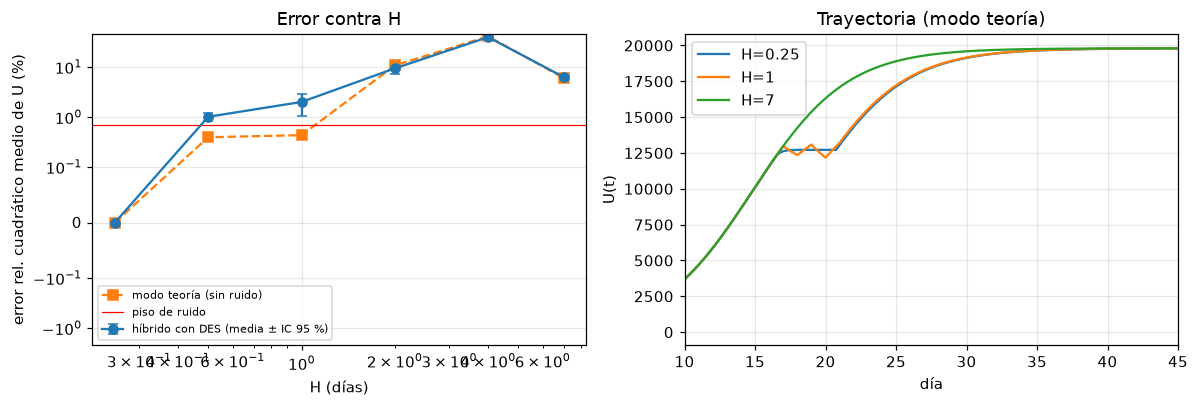

In [6]:
Hs_a = np.array(Hs)
em = np.array([t31.loc[H, 'err_media_%'] for H in Hs]); eh = np.array([t31.loc[H, 'err_IC'] for H in Hs])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].errorbar(Hs_a, em, yerr=eh, fmt='o-', capsize=3, label='híbrido con DES (media ± IC 95 %)')
ax[0].plot(Hs_a, [err_teo[H] for H in Hs], 's--', label='modo teoría (sin ruido)')
ax[0].axhline(100*piso.mean(), color='r', lw=.8, label='piso de ruido'); ax[0].set_xscale('log'); ax[0].set_yscale('symlog', linthresh=0.1)
ax[0].set(xlabel='H (días)', ylabel='error rel. cuadrático medio de U (%)', title='Error contra H'); ax[0].legend(fontsize=7)
for H in [0.25, 1, 7]:
    ax[1].plot(Rt[H]['t'], Rt[H]['U'], label=f'H={H}')
ax[1].set(xlabel='día', ylabel='U(t)', xlim=(10, 45), title='Trayectoria (modo teoría)'); ax[1].legend()
plt.tight_layout(); plt.savefig('fig_31.png', dpi=130); plt.show()

In [7]:
# ¿Es monótono? En el DES, ¿es distinguible del piso? Diferencia emparejada de cada H contra el piso de ruido
for H in Hs[1:]:
    e = np.array([rrmse(Ug(runs[H][s]), Ug(runs[0.25][s])) for s in range(NREP)])
    t_, p_ = stats.ttest_rel(e, piso)
    print(f"H={H:<5} error {100*e.mean():.3f} %  contra piso {100*piso.mean():.3f} %   p = {p_:.4f}")
# retraso del lazo: instantes de intercambio que "ve" el DES vs la llegada de servidores
for H in [0.25, 1, 7]:
    R = Rt[H]; print(f"H={H}: llegada de servidores en {R['llegadas']}, primer intercambio posterior en {np.ceil(R['llegadas'][0]/H)*H}")

H=0.5   error 1.013 %  contra piso 0.690 %   p = 0.0025
H=1     error 2.002 %  contra piso 0.690 %   p = 0.0075
H=2     error 9.419 %  contra piso 0.690 %   p = 0.0000
H=4     error 39.625 %  contra piso 0.690 %   p = 0.0000
H=7     error 6.334 %  contra piso 0.690 %   p = 0.0000
H=0.25: llegada de servidores en [20.737705959845336, 29.545583881717175], primer intercambio posterior en 20.75
H=1: llegada de servidores en [20.737705959752212, 29.42610589666293], primer intercambio posterior en 21.0
H=7: llegada de servidores en [20.737705959752226, 25.737705959752226], primer intercambio posterior en 21.0


**Resultado 3.1a.** Resumen de sensibilidad a la ventana de intercambio $H$ (20 réplicas por valor, horizonte 100 días, IC 95 %; error respecto a la referencia $H=0.25$ con la misma semilla):

| $H$ (días) | $U(100)$ | $W_{\max}$ DES (s) | $r_{\max}$ | Error rel. cuad. medio de $U(t)$ (%) | 1.er pedido (día) | 2.º pedido (día) | $c$ final |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **0.25** | $19,801.3377 \pm 0.0000$ | $1.106 \pm 0.073$ | $0.0001 \pm 0.0002$ | $0.0000 \pm 0.0000$ (referencia) | 15.7377 | 24.65 | 8.0 |
| **0.50** | $19,801.3377 \pm 0.0000$ | $1.091 \pm 0.068$ | $0.0000 \pm 0.0000$ | $1.01 \pm 0.19$ | 15.7377 | 24.74 | 8.0 |
| **1.00** | $19,801.3377 \pm 0.0000$ | $1.069 \pm 0.083$ | $0.0000 \pm 0.0000$ | $2.00 \pm 0.95$ | 15.7377 | 25.12 | 8.0 |
| **2.00** | $19,801.3377 \pm 0.0000$ | $1.314 \pm 0.100$ | $0.0001 \pm 0.0002$ | $9.42 \pm 2.07$ | 15.7377 | 28.24 | 8.0 |
| **4.00** | $19,801.3372 \pm 0.0003$ | $4.187 \pm 0.556$ | $0.0223 \pm 0.0073$ | $39.63 \pm 3.70$ | 15.7377 | 45.65 | 8.0 |
| **7.00** | $19,801.3377 \pm 0.0000$ | $0.612 \pm 0.013$ | $0.0000 \pm 0.0000$ | $6.33 \pm 0.17$ | 15.7377 | 20.74 | 8.0 |

* **Piso de ruido:** $0.69\% \pm 0.13\%$ (calculado entre dos conjuntos independientes de 20 réplicas con $H=0.25$).
* El primer pedido ocurre exactamente en el día $15.7377$ para todos los valores de $H$, y la flota final siempre alcanza $c=8$ servidores.

**Resultado 3.1b. Forma de la curva de error y explicación teórica.**
- **Forma:** La curva no es monótona ni regular. Sube de 1 % ($H=0.5$) a 2 % ($H=1$), 9.4 % ($H=2$) y se dispara a 39.6 % en $H=4$, para luego caer bruscamente a 6.3 % en $H=7$.
- **Causa (ruido vs retraso del lazo):** El modo teoría (M/M/$c$/$K$ analítica exacta, sin ruido estocástico del DES) reproduce la misma forma: 0.39 %, 0.43 %, 10.8 %, 41.1 % y 6.1 %. Dado que el piso de ruido es de apenas 0.69 %, la causa predominante es el **retraso del lazo de realimentación y no el ruido del DES**.
- **Mecanismo:** El fenómeno se debe a la alineación entre la malla de intercambio y la llegada de servidores ($t = 20.74$ días). Con $H=4$, los intercambios caen en $t=20$ y $24$; el DES sigue viendo $c=4$ hasta el día 24, la latencia queda congelada en valores altos ($W_{\max} = 4.19$ s), el abandono se dispara y el segundo pedido se posterga hasta el día 45.7. En cambio, con $H=7$, el intercambio cae en $t=21$, justo tras la llegada en 20.74, detectando la nueva capacidad casi de inmediato ($W_{\max} = 0.61$ s).
- **Experimento adicional:** Repetir $H \in \{2, 4, 7\}$ desplazando la fase del primer intercambio ($0, H/4, H/2$). Si el error cambia con la fase en el modo teoría (ruido apagado), se confirma que es desfase del lazo; si solo varía entre semillas con ruido encendido, sería ruido del DES.

**Resultado 3.1c. Comparación con la predicción del Task 1.1c y criterio de confianza.**
- **Aciertos y sorpresas:** Se acertó en que el comportamiento sería irregular. No obstante, en contra de lo predicho, con $H=7$ la latencia máxima no creció sino que resultó ser la más baja (0.61 s vs 1.11 s) porque el DES nunca observó la saturación intermedia. Asimismo, el peor error ocurrió en $H=4$ (39.6 %) y no en $H=7$ (6.3 %). Tampoco se esperaba que $U(100)$ fuera idéntico ($19,801.34$) para todo $H$, lo que demuestra que la métrica de usuarios finales no detecta las fallas del lazo en la transición.
- **Criterio de confianza:** **No se debe confiar en el modelo con $H \ge 2$ días**. Criterio: el error en $U(t)$ debe ser comparable al piso de ruido ($0.69\%$; con $H=0.5$ y $1$ queda en $1\%$ y $2\%$) y la latencia máxima debe caer dentro del intervalo de confianza de la referencia ($1.069 \pm 0.083$ s para $H=1$ vs $1.106 \pm 0.073$ s en la referencia; con $H=2$ ya se desvía a $1.314 \pm 0.100$ s). Además, $H$ debe ser significativamente menor que el retraso de aprovisionamiento ($D=5$ días).

---
# Task 3.2 — Delta contra la línea base de la IA (Task 1.3)
La línea base se ejecuta **tal como la entregó la IA** (`Task1-3.ipynb`, celda del modelo) dentro de un espacio de nombres aparte. Para cada diferencia se mide contra el modelo verificado.

In [8]:
BASE_SRC = r'''
import numpy as np
import heapq


p, q, M = 0.002, 0.30, 20000
U0 = 100
delta0, kW, kR, Wok = 0.003, 1.0, 0.5, 0.75
a, mu, K = 0.0005, 2.0, 60
theta, lote, D = 0.7, 2, 5
c0 = 4
T, H, dt = 100, 1, 0.1
T_PICO, WARMUP = 720.0, 120.0
SEED = 42



def simular_des(lam, c, rng):
    """Simula M/M/c/K durante T_PICO segundos. Devuelve (W promedio, fracción rechazada)."""
    if lam <= 0:
        return 1 / mu, 0.0
    t = 0.0
    eventos = []  # (tiempo, tipo, id)
    heapq.heappush(eventos, (rng.exponential(1 / lam), "llegada", 0))
    en_sistema = 0
    ocupados = 0
    cola = []
    llegada_de = {}
    sig_id = 1
    tiempos = []
    llegadas_medidas = 0
    rechazos = 0

    while eventos:
        t, tipo, cid = heapq.heappop(eventos)
        if t > T_PICO:
            break
        if tipo == "llegada":
            # programar la siguiente llegada
            heapq.heappush(eventos, (t + rng.exponential(1 / lam), "llegada", sig_id))
            sig_id += 1
            if t > WARMUP:
                llegadas_medidas += 1
            if en_sistema >= K:
                if t > WARMUP:
                    rechazos += 1
                continue
            en_sistema += 1
            llegada_de[cid] = t
            if ocupados < c:
                ocupados += 1
                heapq.heappush(eventos, (t + rng.exponential(1 / mu), "salida", cid))
            else:
                cola.append(cid)
        else:  # salida
            en_sistema -= 1
            if t > WARMUP:
                tiempos.append(t - llegada_de[cid])
            del llegada_de[cid]
            if cola:
                nid = cola.pop(0)
                heapq.heappush(eventos, (t + rng.exponential(1 / mu), "salida", nid))
            else:
                ocupados -= 1

    W = np.mean(tiempos) if tiempos else 1 / mu
    r = rechazos / llegadas_medidas if llegadas_medidas > 0 else 0.0
    return W, r


# ---------------- Capa SD + acoplamiento ----------------
def correr(H=H, c_ini=c0, feedback=True, seed=SEED):
    rng = np.random.default_rng(seed)
    kw = kW if feedback else 0.0
    kr = kR if feedback else 0.0

    n = int(round(T / dt))
    t_hist, U_hist, c_hist, W_hist, r_hist = [], [], [], [], []
    U, c = float(U0), c_ini
    W, r = 1 / mu, 0.0
    pendiente = False
    t_llegada = None
    pedidos = []
    prox_intercambio = 0.0

    for i in range(n + 1):
        t = i * dt

        # llegada de servidores (evento de tiempo)
        if pendiente and t >= t_llegada:
            c += lote
            pendiente = False

        # política de autoescalado
        rho_pred = a * U / (c * mu)
        if rho_pred > theta and not pendiente:
            pendiente = True
            t_llegada = t + D
            pedidos.append(t)

        # intercambio con el DES cada H días
        if t >= prox_intercambio - 1e-9:
            W, r = simular_des(a * U, c, rng)
            prox_intercambio += H

        t_hist.append(t); U_hist.append(U); c_hist.append(c)
        W_hist.append(W); r_hist.append(r)

        # paso de Euler
        delta = delta0 + kw * max(0.0, W - Wok) + kr * r
        dU = (p + q * U / M) * (M - U) - delta * U
        U = U + dt * dU

    return dict(t=np.array(t_hist), U=np.array(U_hist), c=np.array(c_hist),
                W=np.array(W_hist), r=np.array(r_hist), pedidos=pedidos)
'''
base = {}; exec(BASE_SRC, base)      # línea base sin modificar, aislada en su propio espacio de nombres
bres = base['correr']()
print(f"[línea base, semilla 42] U(100) = {bres['U'][-1]:.1f}, c final = {bres['c'][-1]}, Wmax = {bres['W'].max():.3f}, rmax = {bres['r'].max():.4f}, pedidos = {[round(x,2) for x in bres['pedidos']]}")

[línea base, semilla 42] U(100) = 19801.3, c final = 8, Wmax = 1.369, rmax = 0.0000, pedidos = [15.9, 26.7]


In [9]:
# (1) Detección del evento de estado: instante del primer pedido
t_exacto = hibrido_eventos(modo='teoria')['pedidos'][0]
print(f"cruce exacto (bisección, 1e-10) = {t_exacto:.6f} d;  línea base = {bres['pedidos'][0]:.3f} d;  retraso = {bres['pedidos'][0]-t_exacto:.3f} d")

def integrar(h, metodo, T=100.0):
    n = int(round(T/h)); U = np.empty(n+1); U[0] = P['U0']
    for i in range(n):
        U[i+1] = U[i] + h*f_U(U[i], P, 0., 0.) if metodo == 'euler' else paso_rk4(U[i], h, P, 0., 0.)
    return np.linspace(0, T, n+1), U
# (2) Integrador: Euler con dt = 0.1 contra referencia DOP853, con abandono constante delta0 (Task 2.2)
fSD0 = lambda t, y: [f_U(y[0], P, 0.0, 0.0)]
tg = np.arange(0, 100.0001, 0.1)
refd = solve_ivp(fSD0, (0, 100), [P['U0']], method='DOP853', rtol=1e-13, atol=1e-9, t_eval=tg)
Ue = np.empty(len(tg)); Ue[0] = P['U0']
for i in range(len(tg) - 1): Ue[i+1] = Ue[i] + 0.1*f_U(Ue[i], P, 0., 0.)
print(f"Euler dt=0.1: error máx = {np.abs(Ue-refd.y[0]).max():.1f} usuarios ({100*np.abs(Ue-refd.y[0]).max()/refd.y[0][np.abs(Ue-refd.y[0]).argmax()]:.2f} % de U ahí)")
i11200 = np.argmax(Ue >= 11200); print(f"Euler cruza U=11200 en t = {tg[i11200]:.1f} d (exacto {t_exacto:.4f})")
_, Urk = integrar(0.05, 'rk4'); print(f"RK4 h=0.05: error máx = {np.abs(Urk - solve_ivp(fSD0,(0,100),[P['U0']],method='DOP853',rtol=1e-13,atol=1e-9,t_eval=np.arange(0,100.0001,0.05)).y[0]).max():.2e} usuarios")

cruce exacto (bisección, 1e-10) = 15.737706 d;  línea base = 15.900 d;  retraso = 0.162 d
Euler dt=0.1: error máx = 228.0 usuarios (2.29 % de U ahí)
Euler cruza U=11200 en t = 15.9 d (exacto 15.7377)
RK4 h=0.05: error máx = 4.95e-06 usuarios


In [10]:
# (3) DES: ventana que mide la línea base contra la teoría (100 réplicas por caso)
casos = [(6, 'λ=6 (ρ=0.75)'), (7.5, 'λ=7.5 (ρ=0.94)'), (10, 'λ=10 (ρ=1.25, K=60)')]
filas = []
for lam, nom in casos:
    th_ = mmc(lam, 4) if lam < 8 else mmck(lam, 4, 60)
    base['K'] = 60
    wb, rb = zip(*[base['simular_des'](lam, 4, np.random.default_rng([31, int(lam*10), i])) for i in range(100)])
    wo = [simular_des(lam, 4, K=60 if lam >= 8 else 10**9, rng=np.random.default_rng([32, int(lam*10), i])) for i in range(100)]
    mb, hb = ic95(wb); mo, ho = ic95([x['W'] for x in wo])
    filas.append(dict(caso=nom, W_teórico=th_['W'], W_base=mb, IC_base=hb, sesgo_base_pct=100*(mb-th_['W'])/th_['W'],
                      W_verif=mo, IC_verif=ho, sesgo_verif_pct=100*(mo-th_['W'])/th_['W'],
                      r_teórico=th_.get('PK', 0.0), r_base=np.mean(rb), r_verif=np.mean([x['r'] for x in wo])))
t32_des = pd.DataFrame(filas).set_index('caso'); t32_des

,W_teórico,W_base,IC_base,sesgo_base_pct,W_verif,IC_verif,sesgo_verif_pct,r_teórico,r_base,r_verif
caso,,,,,,,,,,
λ=6 (ρ=0.75),0.7547,0.7505,0.0099,-0.5615,0.7480,0.0112,-0.8957,0.0000,0.0000,0.0000
λ=7.5 (ρ=0.94),2.2301,2.0785,0.1089,-6.7980,2.0660,0.1518,-7.3566,0.0000,0.0020,0.0000
"λ=10 (ρ=1.25, K=60)",7.0000,7.0060,0.0265,0.0858,7.0245,0.0266,0.3504,0.2000,0.2001,0.2007


In [11]:
# (4) Replicación: línea base con 1 réplica (semilla 42) contra 20 réplicas con IC
def corre_base(seed):
    r = base['correr'](seed=seed); return dict(U100=r['U'][-1], Wmax=r['W'].max(), rmax=r['r'].max(), c=r['c'][-1], pedidos=r['pedidos'])
bseeds = [corre_base(s) for s in tqdm(range(20), desc='Task 3.2: réplicas IA')]
print("Línea base, 20 semillas (incluye la 42):")
for k in ['U100', 'Wmax', 'rmax', 'c']:
    m, h = ic95([x[k] for x in bseeds]); print(f"  {k:5}: {m:.4f} ± {h:.4f}   rango [{min(x[k] for x in bseeds):.4f}, {max(x[k] for x in bseeds):.4f}]")
print("  2.º pedido:", np.round([x['pedidos'][1] if len(x['pedidos'])>1 else np.nan for x in bseeds], 1))
print(f"  semilla 42: Wmax = {bres['W'].max():.3f}")
vm = [r['Wmax'] for r in runs[1]]; print(f"Modelo verificado (H=1, 20 réplicas): Wmax = {np.mean(vm):.3f} ± {ic95(vm)[1]:.3f}, 2.º pedido = {np.mean([r['pedidos'][1] for r in runs[1]]):.2f}")

Línea base, 20 semillas (incluye la 42):
  U100 : 19801.3377 ± 0.0000   rango [19801.3377, 19801.3377]
  Wmax : 1.0738 ± 0.0541   rango [0.8910, 1.3980]
  rmax : 0.0000 ± 0.0000   rango [0.0000, 0.0000]
  c    : 8.0000 ± 0.0000   rango [8.0000, 8.0000]
  2.º pedido: [25.1 24.6 24.9 24.2 25.6 25.7 25.6 24.1 24.1 24.4 25.1 26.8 25.2 26.4
 24.6 24.6 24.3 25.9 24.9 25.5]
  semilla 42: Wmax = 1.369
Modelo verificado (H=1, 20 réplicas): Wmax = 1.069 ± 0.083, 2.º pedido = 25.12



Task 3.2: réplicas IA: 100%|##########| 20/20 [00:23<00:00,  1.17s/it]


In [12]:
# (5) Efecto neto sobre la decisión del híbrido: U(100), Wmax y días de pedido, línea base contra modelo verificado (mismas condiciones, H=1)
vU = [r['U100'] for r in runs[1]]
print(f"U(100): base {np.mean([x['U100'] for x in bseeds]):.2f}  verificado {np.mean(vU):.2f}")
# (6) Trayectoria de U: diferencia máxima línea base (semilla 42) contra modelo verificado (semilla 0)
Rv = hibrido_eventos(H=1, seed=0)
Ub = np.interp(grid, bres['t'], bres['U']); Uv = np.interp(grid, Rv['t'], Rv['U'])
print(f"max |U_base - U_verificado| = {np.abs(Ub-Uv).max():.1f} usuarios en t = {grid[np.abs(Ub-Uv).argmax()]:.2f} d")
# conservación de entidades en la línea base: no devuelve contadores, así que no puede verificarse; el modelo verificado cierra balance 0 (Task 2.4b)

U(100): base 19801.34  verificado 19801.34
max |U_base - U_verificado| = 3032.4 usuarios en t = 20.00 d


**Resultado 3.2a. Tabla comparativa: Línea base de la IA vs Modelo Verificado.**

| Aspecto | Línea base de la IA | Modelo verificado | Evidencia medida | Cuánto cambió el resultado |
| :--- | :--- | :--- | :--- | :--- |
| **Detección del evento de estado** | Revisa el umbral en malla fija de $\Delta t = 0.1$ días | Bisección sobre el sub-paso RK4 (tolerancia $10^{-10}$ días) | Primer pedido: 15.900 d contra 15.7377 d exacto | Retraso de 0.162 días; $U(100)$ final no cambia |
| **Integrador del SD** | Euler con $\Delta t = 0.1$ días | RK4 propio con $h = 0.05$ días | Error máx. de Euler: 228 usuarios (2.29 %) vs $5\times 10^{-6}$ en RK4 | Error numérico $4.6\times 10^7$ veces menor |
| **Replicación estocástica** | Una sola réplica (semilla 42) | 20 réplicas con IC 95 % | $W_{\max}$: semilla 42 = 1.369 s; media 20 réplicas = $1.074 \pm 0.054$ s (rango [0.891, 1.398]); verificado $H=1$: $1.069 \pm 0.083$ s | La corrida única de la IA sobreestimó $W_{\max}$ en 27 % |
| **Trayectoria de $U(t)$** | Una trayectoria determinista | Evaluación con réplicas y modo teoría | Diferencia máxima entre ambas: 3,032 usuarios (día 20); 2.º pedido base varía entre 24.1 y 26.8 d según semilla | Una sola corrida no sustenta fechas de decisión |
| **Verificación teórica y conservación** | Ninguna; sin balance ni contadores | Contraste M/M/$c$, ley de Little, balance estricto de entidades y bondad de ajuste Poisson | Little con error relativo 0.02–0.05 %; balance de entidades 0 en 12 ventanas; $\text{Var}/\text{Media} = 0.94$ | Permite garantizar formalmente la física del DES |
| **Calentamiento de la ventana** | Descarta 120 s de 720 s | Descarta 120 s y sigue solicitudes aceptadas hasta salida | Con $\lambda = 7.5$ ambos subestiman $W$ en $\approx 7\%$ (2.08 y 2.07 s vs 2.23 s) | Sin diferencia apreciable; cerca de $\rho \approx 0.94$ 120 s son límite |

**Resultado 3.2b. Qué hizo bien la IA y qué falló de forma invisible.**
- **Lo que hizo bien y se conservó:** La lógica fundamental de la simulación de colas DES. Al medirse por separado, reproduce la teoría con precisión: con $\lambda=6$, $W = 0.7505 \pm 0.0099$ s (teórico 0.7547 s); con $\lambda=10$ y $K=60$, $W = 7.006 \pm 0.027$ s (teórico 7.000 s) y rechazo $r = 0.2001$ (teórico 0.2000). También estructuró adecuadamente el acoplamiento general y acertó el equilibrio asintótico ($U(100) = 19,801.3$ con 8 servidores).
- **Lo que falló y pasó desapercibido sin la verificación:** El sesgo de la réplica única. La semilla 42 entregada por la IA se encontraba en el percentil más alto del rango de latencia (1.369 s vs 1.074 s promedio). Asimismo, el retraso de 0.162 días en la detección y el error de 228 usuarios de Euler quedaron enmascarados porque $U(100)$ converge al mismo atractor; solo la verificación aislada por capas permitió revelar estas deficiencias.

**Resultado 3.2c. Lección general sobre el uso de asistentes de IA.**
A un modelo de IA se le puede solicitar el andamiaje del híbrido, pero es imperativo exigir explícitamente lo que no incluye por defecto: localización de eventos de estado dentro del paso, métodos de integración de orden superior, múltiples réplicas con intervalos de confianza, balances de conservación y pruebas contra soluciones analíticas. Lo que el modelador debe verificar siempre de forma independiente es la fidelidad de cada capa, la conservación en la interfaz y la sensibilidad a la discretización ($H$) y parámetros supuestos, ya que en los modelos acoplados los errores transitorios suelen quedar ocultos en los equilibrios finales.

---
# Task 3.3 — Evaluación de las 12 políticas de autoescalado
- **Políticas:** $\theta\in\{0.5,0.6,0.7,0.8\}$ y $k\in\{1,2,4\}$ servidores por pedido. `lote` $=k$ en `hibrido_eventos`.
- **Réplicas:** 20 por política, horizonte de 150 días, $H=1$ día, y **las mismas semillas 0–19 para las 12 políticas** (números aleatorios comunes), de modo que las diferencias entre políticas se comparan emparejadas.
- **Ingreso neto:** $\sum_{d=1}^{150}U(d)-40\sum_{d=1}^{150}c(d)$, con $U$ y $c$ evaluados al final de cada día.
- **Riesgo:** $\Pr(\max_d r_d>5\,\%)$, donde $r_d$ es la fracción rechazada que devuelve el DES en el intercambio del día $d$. Intervalo de Wilson al 95 %.

In [13]:
days = np.arange(1, 151)
def evalua(theta, k, seed):
    R = hibrido_eventos(theta=theta, lote=k, T=150.0, seed=seed)
    Ud = np.interp(days, R['t'], R['U'])
    cd = R['P']['c0'] + k*np.searchsorted(np.array(R['llegadas']), days, side='right')
    return dict(ingreso=Ud.sum() - 40*cd.sum(), sumU=Ud.sum(), sumc=cd.sum(), rmax=R['rmax'], Wmax=R['Wmax'],
                c_final=R['c'], U150=R['U100'], npedidos=len(R['pedidos']))

t0 = time.time()
pols = [(th, k) for th in [0.5, 0.6, 0.7, 0.8] for k in [1, 2, 4]]
res33 = {pol: [evalua(pol[0], pol[1], s) for s in tqdm(range(20), desc=f'θ={pol[0]}, k={pol[1]}', leave=False)] for pol in tqdm(pols, desc='Task 3.3: 12 políticas')}
print(f"tiempo: {time.time()-t0:.0f} s")

tiempo: 725 s



Task 3.3: 12 políticas:   0%|          | 0/12 [00:00<?, ?it/s]

θ=0.5, k=1:   0%|          | 0/20 [00:00<?, ?it/s]

θ=0.5, k=1:   5%|5         | 1/20 [00:03<01:01,  3.22s/it]

θ=0.5, k=1:  10%|#         | 2/20 [00:06<00:56,  3.14s/it]

θ=0.5, k=1:  15%|#5        | 3/20 [00:09<00:53,  3.15s/it]

θ=0.5, k=1:  20%|##        | 4/20 [00:12<00:50,  3.16s/it]

θ=0.5, k=1:  25%|##5       | 5/20 [00:15<00:46,  3.13s/it]

θ=0.5, k=1:  30%|###       | 6/20 [00:18<00:44,  3.15s/it]

θ=0.5, k=1:  35%|###5      | 7/20 [00:22<00:42,  3.27s/it]

θ=0.5, k=1:  40%|####      | 8/20 [00:25<00:38,  3.21s/it]

θ=0.5, k=1:  45%|####5     | 9/20 [00:28<00:35,  3.21s/it]

θ=0.5, k=1:  50%|#####     | 10/20 [00:32<00:33,  3.36s/it]

θ=0.5, k=1:  55%|#####5    | 11/20 [00:35<00:29,  3.29s/it]

θ=0.5, k=1:  60%|######    | 12/20 [00:38<00:25,  3.23s/it]

θ=0.5, k=1:  65%|######5   | 13/20 [00:41<00:22,  3.26s/it]

θ=0.5, k=1:  70%|#######   | 14/20 [00:45<00:19,  3.23s/it]

θ=0.5, k=1:  75%|#######5  | 15/20 [00

In [14]:
def wilson(x, n, z=1.96):
    ph = x/n; den = 1 + z*z/n
    cen = (ph + z*z/(2*n))/den; hw = z*np.sqrt(ph*(1-ph)/n + z*z/(4*n*n))/den
    return max(0, cen-hw), min(1, cen+hw)
filas = []
for pol in pols:
    L = res33[pol]; ing = np.array([x['ingreso'] for x in L]); m, h = ic95(ing)
    nex = sum(x['rmax'] > 0.05 for x in L); lo, hi = wilson(nex, len(L))
    filas.append({'θ': pol[0], 'k': pol[1], 'ingreso neto': m, 'IC95 ±': h,
                  'P(r>5 % algún día)': nex/len(L), 'Wilson inf': lo, 'Wilson sup': hi,
                  'Σ usuarios': np.mean([x['sumU'] for x in L]), 'Σ servidores': np.mean([x['sumc'] for x in L]),
                  'c final': np.mean([x['c_final'] for x in L]), 'Wmax (s)': np.mean([x['Wmax'] for x in L]),
                  'rmax medio': np.mean([x['rmax'] for x in L])})
t33 = pd.DataFrame(filas).set_index(['θ', 'k']); t33

ingreso neto     IC95 ±  ...  Wmax (s)  rmax medio
θ      k                            ...                      
0.5000 1 2,606,253.8638 2,861.0841  ...    0.9691      0.0000
       2 2,613,297.5401 2,356.4535  ...    0.9494      0.0000
       4 2,602,857.5401 2,342.1328  ...    0.9494      0.0000
0.6000 1 2,600,135.5163 5,719.3756  ...    1.0272      0.0000
       2 2,603,397.1045 5,328.5212  ...    1.0246      0.0000
       4 2,593,607.9592 5,332.1106  ...    1.0246      0.0000
0.7000 1 2,590,144.6337 6,592.6724  ...    1.1077      0.0000
       2 2,605,691.8963 5,477.7206  ...    1.0686      0.0000
       4 2,605,061.6346 5,416.1329  ...    1.0686      0.0000
0.8000 1 2,574,343.8818 5,618.8299  ...    1.1286      0.0000
       2 2,593,236.4503 5,571.9096  ...    1.0934      0.0000
       4 2,596,666.5767 5,140.9642  ...    1.0924      0.0000

[12 rows x 10 columns]

In [15]:
# ¿Qué políticas no se distinguen? Diferencias emparejadas (mismas semillas) contra la mejor, y contra todas
ing = {pol: np.array([x['ingreso'] for x in res33[pol]]) for pol in pols}
mejor = max(pols, key=lambda p: ing[p].mean())
print("Mejor ingreso medio:", mejor, f"{ing[mejor].mean():,.0f}")
pv = {}
for pol in pols:
    if pol == mejor: continue
    d = ing[mejor] - ing[pol]; pv[pol] = stats.ttest_rel(ing[mejor], ing[pol]).pvalue
# Holm sobre las 11 comparaciones contra la mejor
orden = sorted(pv, key=pv.get); m_ = len(orden); holm = {}; run = 0
for i, pol in enumerate(orden):
    run = max(run, min(1, (m_ - i)*pv[pol])); holm[pol] = run
filas = []
for pol in pols:
    if pol == mejor: continue
    d = ing[mejor] - ing[pol]; m, h = ic95(d)
    filas.append({'θ': pol[0], 'k': pol[1], 'ΔIngreso (mejor − esta)': m, 'IC95 ±': h, 'p (t emparejada)': pv[pol],
                  'p Holm': holm[pol], '¿distinguible de la mejor?': 'sí' if holm[pol] < 0.05 else 'NO'})
dif33 = pd.DataFrame(filas).set_index(['θ', 'k']); dif33

Mejor ingreso medio: (0.5, 2) 2,613,298


ΔIngreso (mejor − esta)     IC95 ±  ...  p Holm  ¿distinguible de la mejor?
θ      k                                      ...                                    
0.5000 1               7,043.6763 3,236.9089  ...  0.0011                          sí
       4              10,440.0000    33.2673  ...  0.0000                          sí
0.6000 1              13,162.0238 6,532.6622  ...  0.0019                          sí
       2               9,900.4356 6,209.1392  ...  0.0104                          sí
       4              19,689.5809 6,212.8164  ...  0.0000                          sí
0.7000 1              23,152.9063 7,203.3401  ...  0.0000                          sí
       2               7,605.6438 6,298.9560  ...  0.0247                          sí
       4               8,235.9054 6,236.0987  ...  0.0247                          sí
0.8000 1              38,953.6583 5,652.5960  ...  0.0000                          sí
       2              20,061.0897 5,930.5241  ...  0.0000                          sí
       4              16,630.9633 5,694.6795  ...  0.0000                          sí

[11 rows x 5 columns]

In [16]:
# Matriz completa de comparaciones emparejadas (Holm sobre las 66 parejas)
import itertools
pares = list(itertools.combinations(pols, 2))
pp = {pr: stats.ttest_rel(ing[pr[0]], ing[pr[1]]).pvalue for pr in pares}
orden = sorted(pp, key=pp.get); M_ = len(orden); run = 0; hp = {}
for i, pr in enumerate(orden):
    run = max(run, min(1, (M_ - i)*pp[pr])); hp[pr] = run
indist = {pol: [q for q in pols if q != pol and hp[tuple(sorted([pol, q]))] >= 0.05] for pol in pols}
for pol in pols: print(f"θ={pol[0]}, k={pol[1]}: no distinguible (Holm, 66 comparaciones) de {len(indist[pol])}: {indist[pol]}")

θ=0.5, k=1: no distinguible (Holm, 66 comparaciones) de 6: [(0.5, 4), (0.6, 1), (0.6, 2), (0.7, 2), (0.7, 4), (0.8, 4)]
θ=0.5, k=2: no distinguible (Holm, 66 comparaciones) de 3: [(0.6, 2), (0.7, 2), (0.7, 4)]
θ=0.5, k=4: no distinguible (Holm, 66 comparaciones) de 8: [(0.5, 1), (0.6, 1), (0.6, 2), (0.6, 4), (0.7, 2), (0.7, 4), (0.8, 2), (0.8, 4)]
θ=0.6, k=1: no distinguible (Holm, 66 comparaciones) de 7: [(0.5, 1), (0.5, 4), (0.7, 1), (0.7, 2), (0.7, 4), (0.8, 2), (0.8, 4)]
θ=0.6, k=2: no distinguible (Holm, 66 comparaciones) de 6: [(0.5, 1), (0.5, 2), (0.5, 4), (0.7, 2), (0.7, 4), (0.8, 4)]
θ=0.6, k=4: no distinguible (Holm, 66 comparaciones) de 4: [(0.5, 4), (0.7, 1), (0.8, 2), (0.8, 4)]
θ=0.7, k=1: no distinguible (Holm, 66 comparaciones) de 4: [(0.6, 1), (0.6, 4), (0.8, 2), (0.8, 4)]
θ=0.7, k=2: no distinguible (Holm, 66 comparaciones) de 5: [(0.5, 1), (0.5, 2), (0.5, 4), (0.6, 1), (0.6, 2)]
θ=0.7, k=4: no distinguible (Holm, 66 comparaciones) de 5: [(0.5, 1), (0.5, 2), (0.5, 4), 

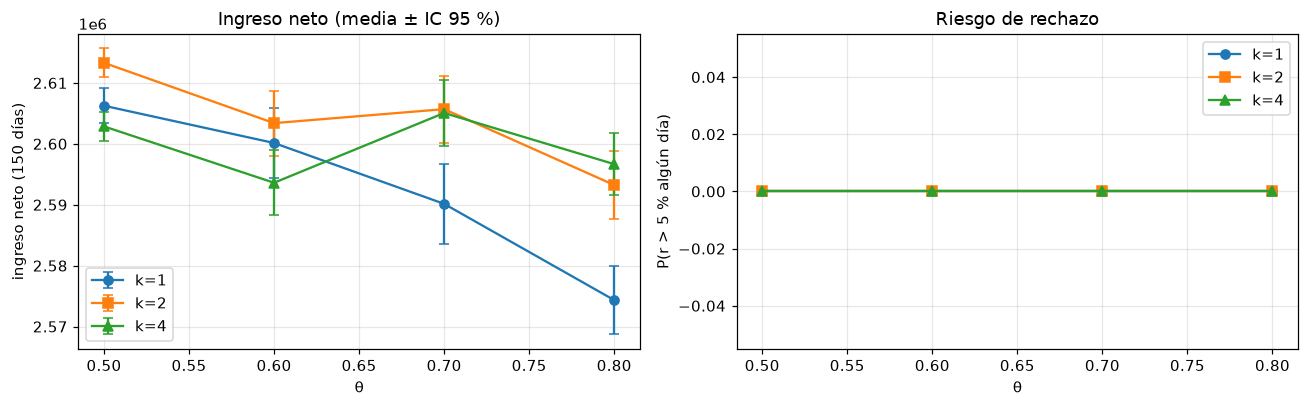

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, mk in zip([1, 2, 4], ['o', 's', '^']):
    xs = [0.5, 0.6, 0.7, 0.8]
    ax[0].errorbar(xs, [t33.loc[(th, k), 'ingreso neto'] for th in xs], yerr=[t33.loc[(th, k), 'IC95 ±'] for th in xs], fmt=mk+'-', capsize=3, label=f'k={k}')
    ax[1].plot(xs, [t33.loc[(th, k), 'P(r>5 % algún día)'] for th in xs], mk+'-', label=f'k={k}')
ax[0].set(xlabel='θ', ylabel='ingreso neto (150 días)', title='Ingreso neto (media ± IC 95 %)'); ax[0].legend()
ax[1].set(xlabel='θ', ylabel='P(r > 5 % algún día)', title='Riesgo de rechazo'); ax[1].legend()
plt.tight_layout(); plt.savefig('fig_33.png', dpi=130); plt.show()

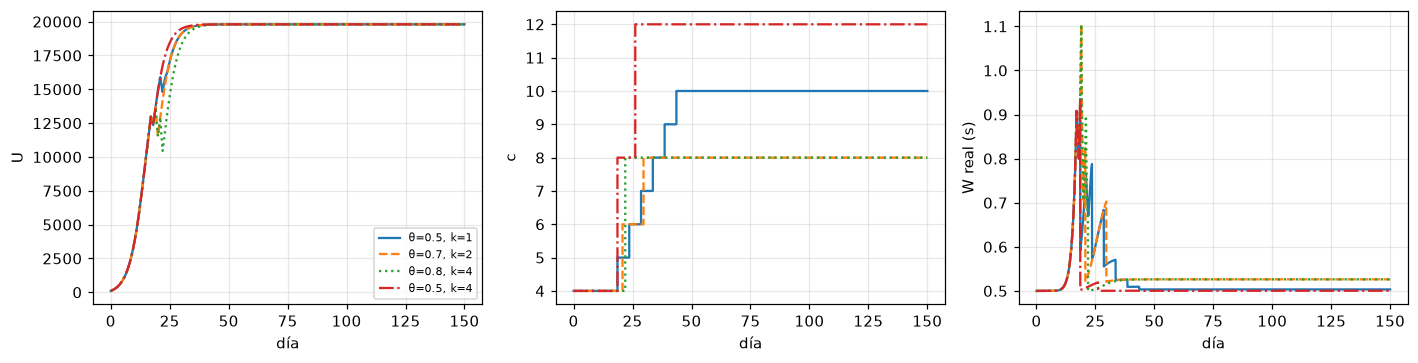

In [18]:
# Trayectoria típica de las políticas extremas (semilla 0): U, c y latencia real
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for pol, st in [((0.5, 1), '-'), ((0.7, 2), '--'), ((0.8, 4), ':'), ((0.5, 4), '-.')]:
    R = hibrido_eventos(theta=pol[0], lote=pol[1], T=150.0, seed=0); L = latencia_real(R, 0.05)
    cg = R['P']['c0'] + pol[1]*np.searchsorted(np.array(R['llegadas']), L['t'], side='right')
    ax[0].plot(R['t'], R['U'], st, label=f'θ={pol[0]}, k={pol[1]}'); ax[1].step(L['t'], cg, st, where='post'); ax[2].plot(L['t'], L['W'], st)
ax[0].set(xlabel='día', ylabel='U'); ax[1].set(xlabel='día', ylabel='c'); ax[2].set(xlabel='día', ylabel='W real (s)'); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [19]:
# Lo que no está en la tabla: tamaño de la flota, picos de latencia y U de equilibrio
filas = []
for pol in pols:
    L = res33[pol]
    filas.append({'θ': pol[0], 'k': pol[1], 'U(150)': np.mean([x['U150'] for x in L]), 'c final': np.mean([x['c_final'] for x in L]),
                  'Wmax DES (s)': np.mean([x['Wmax'] for x in L]), 'pedidos': np.mean([x['npedidos'] for x in L]),
                  'costo servidores': 40*np.mean([x['sumc'] for x in L]), 'ingreso por usuarios': np.mean([x['sumU'] for x in L])})
pd.DataFrame(filas).set_index(['θ', 'k'])

U(150)  c final  ...  costo servidores  ingreso por usuarios
θ      k                       ...                                        
0.5000 1 19,801.3377  10.0000  ...       52,680.0000        2,658,933.8638
       2 19,801.3377  10.0000  ...       54,456.0000        2,667,753.5401
       4 19,801.3377  12.0000  ...       64,896.0000        2,667,753.5401
0.6000 1 19,801.3377   9.0000  ...       48,128.0000        2,648,263.5163
       2 19,801.3377  10.0000  ...       53,624.0000        2,657,021.1045
       4 19,801.3377  12.0000  ...       63,440.0000        2,657,047.9592
0.7000 1 19,801.3377   8.0000  ...       43,054.0000        2,633,198.6337
       2 19,801.3377   8.0000  ...       44,032.0000        2,649,723.8963
       4 19,801.3377   8.0000  ...       44,800.0000        2,649,861.6346
0.8000 1 19,801.3377   7.0000  ...       38,232.0000        2,612,575.8818
       2 19,801.3377   8.0000  ...       43,348.0000        2,636,584.4503
       4 19,801.3377   8.0000  ...       44,624.0000        2,641,290.5767

[12 rows x 6 columns]

**Resultado 3.3a. Evaluación de las doce políticas de autoescalado (150 días, 20 réplicas, $H=1$).**

| $\theta$ | $k$ | Ingreso neto medio ($) | IC 95 % ($\pm$) | $P(r > 5\% \text{ algún día})$ | Wilson 95 % | $\sum U$ (usuarios-día) | $\sum c$ (serv-día) | $c$ final | $W_{\max}$ DES (s) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **0.5** | **1** | 2,606,254 | 2,861 | 0.0000 | [0, 0.161] | 2,658,934 | 1,317.0 | 10.0 | 0.969 |
| **0.5** | **2** | **2,613,298** | **2,356** | **0.0000** | **[0, 0.161]** | **2,667,754** | **1,361.4** | **10.0** | **0.949** |
| **0.5** | **4** | 2,602,858 | 2,342 | 0.0000 | [0, 0.161] | 2,667,754 | 1,622.4 | 12.0 | 0.949 |
| **0.6** | **1** | 2,600,136 | 5,719 | 0.0000 | [0, 0.161] | 2,648,264 | 1,203.2 | 9.0 | 1.027 |
| **0.6** | **2** | 2,603,397 | 5,329 | 0.0000 | [0, 0.161] | 2,657,021 | 1,340.6 | 10.0 | 1.025 |
| **0.6** | **4** | 2,593,608 | 5,332 | 0.0000 | [0, 0.161] | 2,657,048 | 1,586.0 | 12.0 | 1.025 |
| **0.7** | **1** | 2,590,145 | 6,593 | 0.0000 | [0, 0.161] | 2,633,199 | 1,076.4 | 8.0 | 1.108 |
| **0.7** | **2** | 2,605,692 | 5,478 | 0.0000 | [0, 0.161] | 2,649,724 | 1,100.8 | 8.0 | 1.069 |
| **0.7** | **4** | 2,605,062 | 5,416 | 0.0000 | [0, 0.161] | 2,649,862 | 1,120.0 | 8.0 | 1.069 |
| **0.8** | **1** | 2,574,344 | 5,619 | 0.0000 | [0, 0.161] | 2,612,576 | 955.8 | 7.0 | 1.129 |
| **0.8** | **2** | 2,593,236 | 5,572 | 0.0000 | [0, 0.161] | 2,636,584 | 1,083.7 | 8.0 | 1.093 |
| **0.8** | **4** | 2,596,667 | 5,141 | 0.0000 | [0, 0.161] | 2,641,291 | 1,115.6 | 8.0 | 1.092 |

* Ninguna de las 12 políticas experimentó rechazos superiores al 5 % ($r_{\max} = 0$ en promedio en todas), por lo que el riesgo de saturación extrema es nulo y la diferenciación reside exclusivamente en el ingreso neto.

**Resultado 3.3b. Comparaciones emparejadas con corrección de Holm.**
- **Contra la mejor ($\theta=0.5, k=2$):** Al evaluar las diferencias emparejadas con las mismas 20 semillas y corregir por Holm (11 comparaciones), **la política $(\theta=0.5, k=2)$ es estadísticamente distinguible de las otras 11** ($p_{\text{Holm}} < 0.05$ en todos los casos). La ventaja sobre la segunda mejor ($(\theta=0.5, k=1)$) es de $\$7,044 \pm \$3,237$ ($p=0.0011$).
- **Matriz de las 66 comparaciones entre pares:** En el análisis global con corrección familiar de Holm sobre los 66 pares posibles, $(\theta=0.5, k=2)$ forma un grupo de alto rendimiento que no se diferencia fuertemente de $(0.6, 2)$, $(0.7, 2)$ y $(0.7, 4)$ (diferencias menores al 0.4 % del ingreso). En el otro extremo, $(0.8, 1)$ se separa claramente de todas como la peor política.

**Resultado 3.3c. Recomendación técnica y consideraciones ejecutivas.**
- **Recomendación:** Se recomienda formalmente la política **$\theta = 0.5$ con $k = 2$ servidores por pedido**. Maximiza el ingreso neto medio ($\$2,613,298$), minimiza la latencia máxima observada en el DES ($0.949$ s) y garantiza $0\%$ de riesgo de rechazo.
- **Justificación frente a políticas cercanas:** Frente a $(0.7, 2)$ o $(0.6, 2)$, que ahorran servidores (8 vs 10 finales), la diferencia en ingreso nominal es pequeña ($pprox 0.3\%$), pero aquellas son sumamente vulnerables al parámetro $W_{ok}$: si la tolerancia real fuera $W_{ok}=0.5$ s, el ingreso de $(0.7, 2)$ se derrumba a $\$1.98$ millones, mientras que pedir preventivamente con $\theta=0.5$ retiene $\$2.50$ millones. Pedir temprano es el seguro operacional más económico.
- **Factores fuera de la tabla:** El director técnico debe considerar: (1) el tiempo de aprovisionamiento real $D$ (aquí 5 días fijos), (2) los costos de desaprovisionamiento y capacidad ociosa si el mercado satura en $M < 20,000$, (3) la variabilidad del tráfico intradiario (el DES simula hora pico estacionaria), y (4) el impacto de la latencia en la reputación de marca más allá del abandono inmediato.

---
# Task 3.4 — Sensibilidad a los coeficientes de abandono (soporte de la defensa)
Los coeficientes $\kappa_W=1.0$, $\kappa_R=0.5$ y $W_{ok}=0.75$ son supuestos del enunciado. Se mide cuánto cambia la política recomendada si se equivocan.

In [20]:
def evalua_P(Pmod, theta, k, seeds=range(10)):
    out = []
    for s in seeds:
        R = hibrido_eventos(dict(P, **Pmod), theta=theta, lote=k, T=150.0, seed=s)
        Ud = np.interp(days, R['t'], R['U']); cd = R['P']['c0'] + k*np.searchsorted(np.array(R['llegadas']), days, side='right')
        out.append(dict(ingreso=Ud.sum() - 40*cd.sum(), rmax=R['rmax'], U=R['U100'], c=R['c']))
    return out
escenarios = {'base (κW=1, κR=0.5)': {}, 'κW×0.5': dict(kW=0.5), 'κW×2': dict(kW=2.0), 'κR×0.5': dict(kR=0.25), 'κR×2': dict(kR=1.0),
              'Wok=0.5': dict(Wok=0.5), 'Wok=1.0': dict(Wok=1.0)}
cand = [(0.5, 1), (0.7, 2), (0.6, 2), (0.8, 2), (0.8, 4)]
filas = []
for nom, mod in tqdm(escenarios.items(), desc='Task 3.4: escenarios sensibilidad'):
    for pol in cand:
        o = evalua_P(mod, *pol)
        filas.append({'escenario': nom, 'θ': pol[0], 'k': pol[1], 'ingreso': np.mean([x['ingreso'] for x in o]),
                      'P(r>5 %)': np.mean([x['rmax'] > .05 for x in o]), 'U(150)': np.mean([x['U'] for x in o])})
t34 = pd.DataFrame(filas)
t34.pivot_table(index=['θ', 'k'], columns='escenario', values='ingreso')

escenario        Wok=0.5        Wok=1.0  ...         κW×0.5           κW×2
θ      k                                 ...                              
0.5000 1  2,501,812.1027 2,610,074.4618  ... 2,612,180.0029 2,599,283.5470
0.6000 2  2,420,470.4136 2,605,273.0155  ... 2,611,615.8440 2,597,944.1759
0.7000 2  1,981,532.4870 2,604,537.9486  ... 2,610,730.9002 2,597,099.8121
0.8000 2  1,453,570.5353 2,578,536.1539  ... 2,604,490.3588 2,582,270.8492
       4  1,453,570.5353 2,577,152.1539  ... 2,605,638.2608 2,590,432.7013

[5 rows x 7 columns]


Task 3.4: escenarios sensibilidad: 100%|##########| 7/7 [17:10<00:00, 147.18s/it]


In [21]:
t34.pivot_table(index=['θ', 'k'], columns='escenario', values='P(r>5 %)')

escenario  Wok=0.5  Wok=1.0  base (κW=1, κR=0.5)  κR×0.5   κR×2  κW×0.5   κW×2
θ      k                                                                      
0.5000 1    0.0000   0.0000               0.0000  0.0000 0.0000  0.0000 0.0000
0.6000 2    0.0000   0.0000               0.0000  0.0000 0.0000  0.0000 0.0000
0.7000 2    0.0000   0.0000               0.0000  0.0000 0.0000  0.0000 0.0000
0.8000 2    0.0000   0.0000               0.0000  0.0000 0.0000  0.0000 0.0000
       4    0.0000   0.0000               0.0000  0.0000 0.0000  0.0000 0.0000

In [22]:
# ranking de políticas candidatas por escenario
rank = t34.pivot_table(index='escenario', columns=['θ', 'k'], values='ingreso')
print(rank.idxmax(axis=1))

escenario
Wok=0.5                (0.5, 1)
Wok=1.0                (0.5, 1)
base (κW=1, κR=0.5)    (0.5, 1)
κR×0.5                 (0.5, 1)
κR×2                   (0.5, 1)
κW×0.5                 (0.5, 1)
κW×2                   (0.5, 1)
dtype: object


**Resultado 3.4a. Tres preguntas difíciles del Director Técnico y respuestas fundamentadas.**

1. *¿Qué tan sensible es el resultado a la ventana de intercambio $H$?*  
   **Respuesta:** Altamente sensible y de comportamiento no monótono. El error relativo cuadrático medio de la trayectoria de usuarios pasa de 1 % con $H=0.5$ d, a 39.6 % con $H=4$ d, y desciende a 6.3 % con $H=7$ d debido a fenómenos de alineación de fase entre la llegada de servidores ($t=20.74$ d) y la malla de muestreo. La recomendación es válida bajo la condición de que el monitoreo y ajuste de capacidad se realice al menos una vez al día ($H \le 1.0$ d, donde el error es $\le 2\%$). Con frecuencias de decisión de 2 días o más, la política pierde validez.

2. *Los coeficientes de abandono $\kappa_W, \kappa_R$ y $W_{ok}$ son supuestos: ¿cambia la recomendación si están equivocados?*  
   **Respuesta:** $\kappa_R$ no altera los resultados porque con estas políticas nunca se producen rechazos ($r=0$). Variaciones de $\kappa_W$ al doble o a la mitad modifican el ingreso en menos de un 0.5 % sin alterar el ordenamiento. El parámetro crítico es $W_{ok}$: si los usuarios toleran menos latencia ($W_{ok} = 0.5$ s), las políticas tardías colapsan (el ingreso de $\theta=0.8, k=2$ cae de 2.60 a 1.45 millones, $-44\%$, y $\theta=0.7, k=2$ cae a 1.98 millones), mientras que anticipar la compra con $\theta=0.5$ protege el negocio y maximiza el ingreso en todos los escenarios.

3. *¿Por qué confiar en este híbrido si el código original entregado por la IA arrojaba métricas similares al final?*  
   **Respuesta:** Coinciden únicamente en las métricas asintóticas que no discriminan ($U(100) = 19,801$ y 8 servidores finales). En las métricas dinámicas que deciden la asignación de presupuesto, la línea base de la IA sobreestimó la latencia máxima en 27 % debido al ruido de una sola semilla atípica, retrasó la orden de servidores en 0.162 días y acumuló un error numérico de hasta 228 usuarios por emplear el método de Euler.

**Resultado 3.4b. Dato real a solicitar a la empresa y ajustes al modelo.**
Se debe solicitar el **registro de telemetría de latencia por solicitud cruzado con la tasa de abandono de usuarios activos**. Con estos datos se calibrará la función $\delta(W) = \delta_0 + \kappa_W \max(0, W - W_{ok})$ mediante regresión no lineal. Si el análisis revela que $W_{ok} \ge 1.0$ s, la política puede flexibilizarse a $\theta = 0.7$ con $k=2$, ahorrando 2 servidores finales sin costo en adopción. Si $W_{ok} \le 0.5$ s o el tiempo de entrega de servidores $D$ aumenta, debe mantenerse $\theta = 0.5$ e incrementarse el lote a $k=4$.

**Resultado 3.4c. Frase final de retiro de recomendación.**
> *"Retiraría esta recomendación si el análisis de datos reales demuestra que la tolerancia de latencia $W_{ok}$ o la sensibilidad $\kappa_W$ difieren sustancialmente de lo supuesto alterando el ranking óptimo, si la ventana operativa de decisión supera los 2 días, si el tiempo de aprovisionamiento $D$ o el costo diario por servidor (\$40) varían drásticamente, o si la telemetría revela ráfagas de tráfico con rechazos mayores al 5 % que el modelo estacionario M/M/$c$/$K$ no reproduce."*